<a href="https://colab.research.google.com/github/FunGrape/Labs_ML_Demchyshyn/blob/main/%D0%9B%D0%A06_%D0%94%D0%B5%D0%BC%D1%87%D0%B8%D1%88%D0%B8%D0%BD_4_9_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [ ]:
df["gender"].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [ ]:
df["smoking_history"].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [ ]:
df.head(10)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
5,Female,20.0,0,0,never,27.32,6.6,85,0
6,Female,44.0,0,0,never,19.31,6.5,200,1
7,Female,79.0,0,0,No Info,23.86,5.7,85,0
8,Male,42.0,0,0,never,33.64,4.8,145,0
9,Female,32.0,0,0,never,27.32,5.0,100,0


Вивести типи даних

In [ ]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [ ]:
df["diabetes"].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [ ]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [ ]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [ ]:
df.duplicated().sum()

np.int64(3854)

In [ ]:
df.drop_duplicates(inplace=True)

Ще раз перевірити баланс цільової змінної

In [ ]:
print(df["diabetes"].value_counts())
print(df["diabetes"].value_counts(normalize=True).round(4))

diabetes
0    87664
1     8482
Name: count, dtype: int64
diabetes
0    0.9118
1    0.0882
Name: proportion, dtype: float64


Побудувати гістограму для цільової змінної


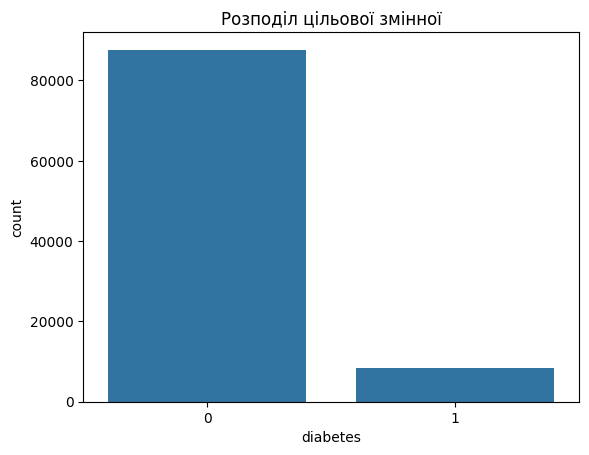

In [ ]:
sns.countplot(x="diabetes", data=df, color="tab:blue")
plt.title("Розподіл цільової змінної")
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
X = df.drop(columns="diabetes")
y = df["diabetes"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print("Частка класу 1: train =", round(y_train.mean(), 4), "| test =", round(y_test.mean(), 4))

(76916, 8) (19230, 8)
Частка класу 1: train = 0.0882 | test = 0.0882


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
cat_cols = ["gender", "smoking_history"]
X_train_enc = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, dtype=int)
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)
print(X_train_enc.shape, X_test_enc.shape)

(76916, 15) (19230, 15)


In [ ]:
X_train_enc.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
X_train_enc.corrwith(y_train).sort_values(ascending=False)

,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


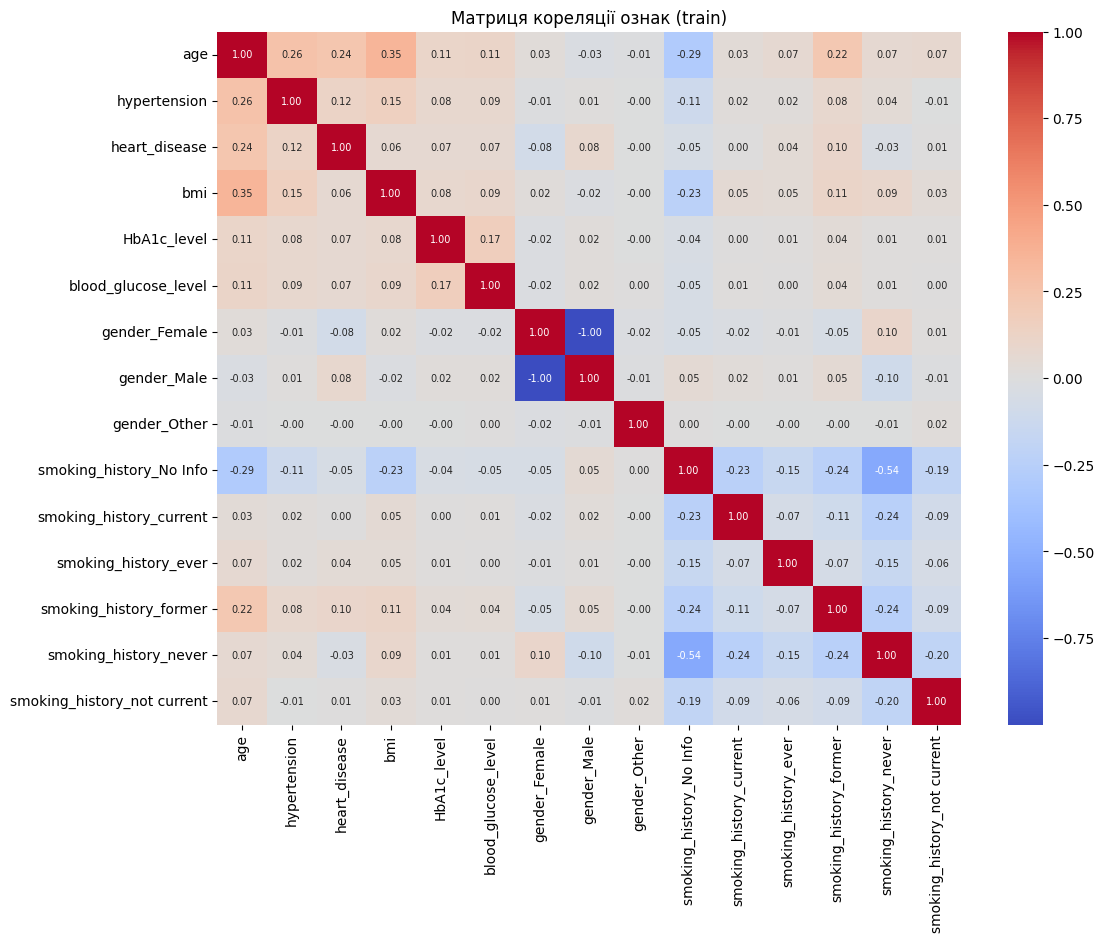

In [ ]:
corr = X_train_enc.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Матриця кореляції ознак (train)")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

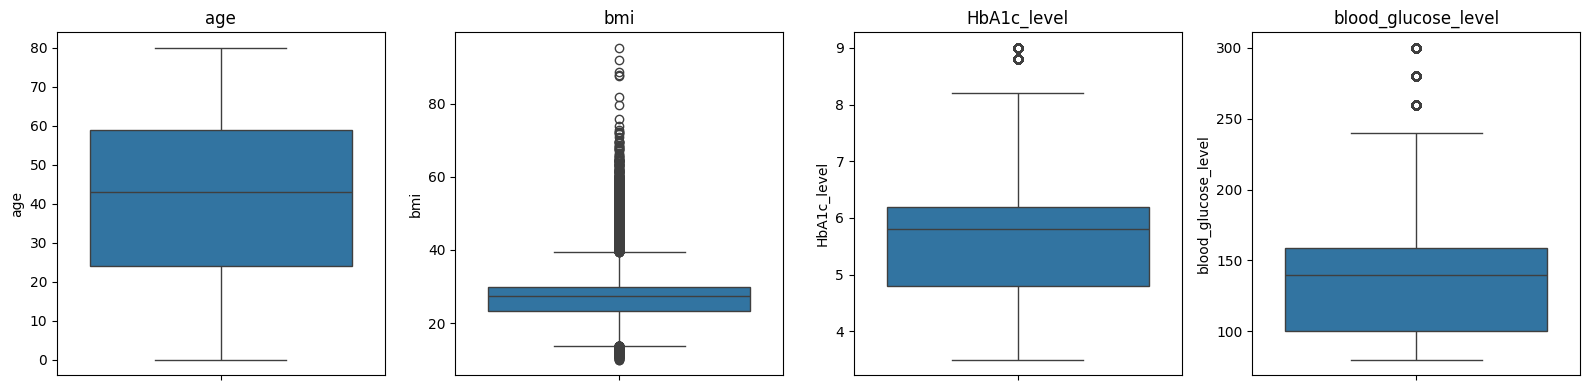

In [ ]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
Q1, Q3 = X_train["bmi"].quantile(0.25), X_train["bmi"].quantile(0.75)
IQR = Q3 - Q1
low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
n_out = ((X_train["bmi"] < low) | (X_train["bmi"] > high)).sum()
print(f"bmi: межі IQR (за train) = [{low:.2f}, {high:.2f}], потенційних викидів: {n_out}. Рядки не видаляємо.")

bmi: межі IQR (за train) = [13.70, 39.54], потенційних викидів: 4244. Рядки не видаляємо.


Перевірити асиметрію розподілів ознак **на train**

In [ ]:
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [ ]:
print("Пропуски в X_train:", X_train_enc.isnull().sum().sum())
print("Пропуски в X_test:", X_test_enc.isnull().sum().sum())

Пропуски в X_train: 0
Пропуски в X_test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_enc)
X_test_sc = scaler.transform(X_test_enc)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
print("До SMOTE:\n", y_train.value_counts())
smote = SMOTE(random_state=42)
X_bal, y_bal = smote.fit_resample(X_train_sc, y_train)
print("Після SMOTE:\n", y_bal.value_counts())

До SMOTE:
 diabetes
0    70130
1     6786
Name: count, dtype: int64
Після SMOTE:
 diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Ridge Classifier": RidgeClassifier(random_state=42),
    "SGD Classifier": SGDClassifier(random_state=42),
    "SVC": SVC(random_state=42),
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


 Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



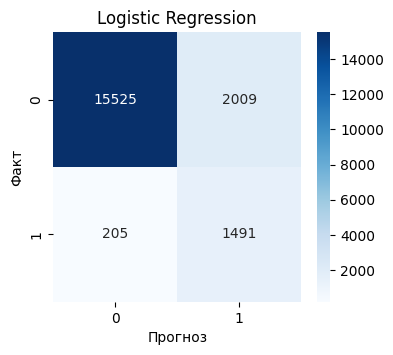

 Ridge Classifier
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



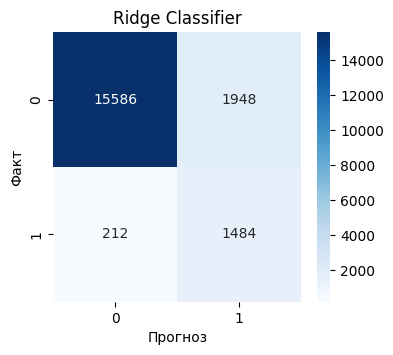

 SGD Classifier
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



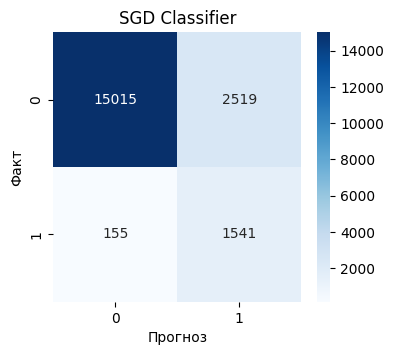

 SVC
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.90      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.89      0.90     19230



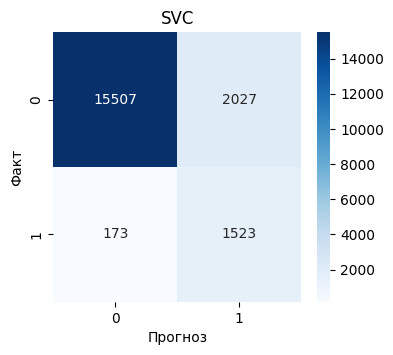

,precision (1),recall (1),F1 (1),accuracy
Logistic Regression,0.4260,0.8791,0.5739,0.8849
Ridge Classifier,0.4324,0.8750,0.5788,0.8877
SGD Classifier,0.3796,0.9086,0.5354,0.8609
SVC,0.4290,0.8980,0.5806,0.8856


In [ ]:
def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[0, 1], yticklabels=[0, 1])
    plt.xlabel("Прогноз")
    plt.ylabel("Факт")
    plt.title(title)
    plt.show()

SVC_N = 20000
rng = np.random.RandomState(42)
svc_idx = rng.choice(len(X_bal), size=SVC_N, replace=False)

base_results = {}
for name, model in models.items():
    if name == "SVC":
        model.fit(X_bal[svc_idx], np.asarray(y_bal)[svc_idx])
    else:
        model.fit(X_bal, y_bal)
    y_pred = model.predict(X_test_sc)
    print("=" * 60, "\n", name)
    print(classification_report(y_test, y_pred))
    plot_cm(y_test, y_pred, name)
    rep = classification_report(y_test, y_pred, output_dict=True)
    base_results[name] = {"precision (1)": rep["1"]["precision"], "recall (1)": rep["1"]["recall"],
                          "F1 (1)": rep["1"]["f1-score"], "accuracy": rep["accuracy"]}
pd.DataFrame(base_results).T.round(4)

Оптимізувати гіперпараметри


In [ ]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10], "model__solver": ["lbfgs", "liblinear"]},
    "Ridge Classifier": {"model__alpha": [0.1, 1, 10, 100]},
    "SGD Classifier": {"model__loss": ["hinge", "log_loss", "modified_huber"],
                       "model__penalty": ["l2", "l1", "elasticnet"],
                       "model__alpha": [0.0001, 0.001]},
    "SVC": {"model__C": [0.1, 1, 10], "model__kernel": ["linear", "rbf"]},
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

 Logistic Regression
Оптимальні параметри: {'model__C': 1, 'model__solver': 'lbfgs'}
Середній F1 на крос-валідації: 0.6098
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



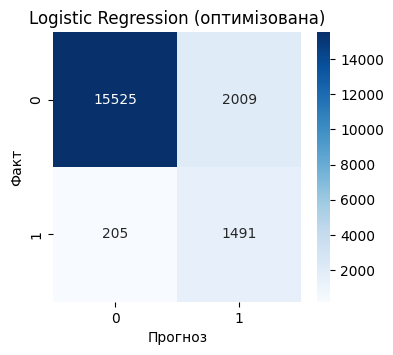

 Ridge Classifier
Оптимальні параметри: {'model__alpha': 100}
Середній F1 на крос-валідації: 0.6587
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



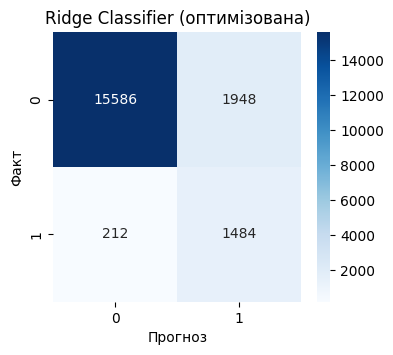

 SGD Classifier
Оптимальні параметри: {'model__alpha': 0.001, 'model__loss': 'log_loss', 'model__penalty': 'l1'}
Середній F1 на крос-валідації: 0.6269
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



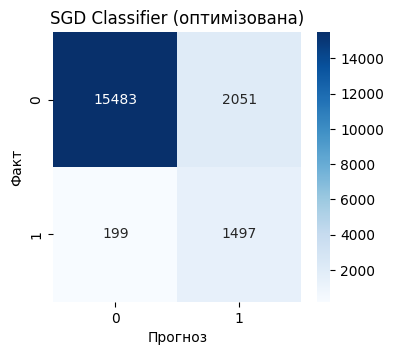

 SVC
Оптимальні параметри: {'model__C': 10, 'model__kernel': 'linear'}
Середній F1 на крос-валідації: 0.5929
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



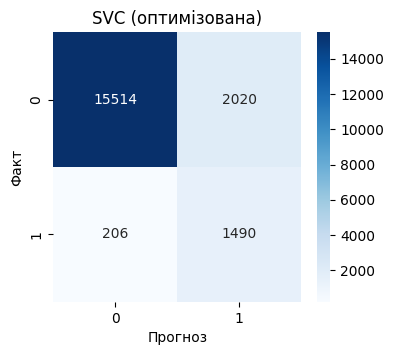

In [ ]:
from sklearn.base import clone

X_svc, _, y_svc, _ = train_test_split(X_train_enc, y_train, train_size=SVC_N,
                                      stratify=y_train, random_state=42)

best_models, best_scores, best_params = {}, {}, {}
for name, model in models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", clone(model)),
    ])
    X_s, y_s = (X_svc, y_svc) if name == "SVC" else (X_train_enc, y_train)
    search = HalvingGridSearchCV(pipe, param_grids[name], cv=3, scoring="f1",
                                 min_resources=300, factor=3, random_state=42,
                                 n_jobs=-1, refit=True)
    search.fit(X_s, y_s)
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    best_params[name] = search.best_params_

    y_pred = search.best_estimator_.predict(X_test_enc)
    print("=" * 60, "\n", name)
    print("Оптимальні параметри:", search.best_params_)
    print("Середній F1 на крос-валідації:", round(search.best_score_, 4))
    print(classification_report(y_test, y_pred))
    plot_cm(y_test, y_pred, name + " (оптимізована)")

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
cv_table = pd.Series(best_scores, name="F1 (cv)").sort_values(ascending=False)
display(cv_table.round(4))
best_name = cv_table.index[0]
best_model = best_models[best_name]
print("Найкраща модель за F1 на крос-валідації:", best_name, "| F1 =", round(cv_table.iloc[0], 4))

,F1 (cv)
Ridge Classifier,0.6587
SGD Classifier,0.6269
Logistic Regression,0.6098
SVC,0.5929


Найкраща модель за F1 на крос-валідації: Ridge Classifier | F1 = 0.6587


In [ ]:
rng = np.random.RandomState(42)
pos = rng.choice(len(X_test_enc), size=10, replace=False)
sample = X_test_enc.iloc[pos]
pred_10 = best_model.predict(sample)
table = pd.DataFrame({
    "Індекс": sample.index,
    "Істинний клас": y_test.iloc[pos].values,
    "Передбачений клас": pred_10,
})
table["Збіг"] = table["Істинний клас"] == table["Передбачений клас"]
table

,Індекс,Істинний клас,Передбачений клас,Збіг
0,36061,0,0,True
1,29824,0,0,True
2,29668,0,1,False
3,11816,0,0,True
4,99242,0,0,True
5,26718,0,0,True
6,53059,0,0,True
7,69294,0,0,True
8,8912,0,1,False
9,37072,0,0,True


**Підсумкові висновки (заповніть самостійно):**
У ході виконання лабораторної роботи № 6 було досліджено процес класифікації та застосовано методи запобігання перенавчанню (регуляризацію, підбір гіперпараметрів) на датасеті прогнозування діабету (diabetes_prediction_dataset.csv).

Основні результати та спостереження:

1. Аналіз та підготовка даних:

- Проведено попередній аналіз структури датасету та перевірено відсутність пропущених значень.

- Виявлено та видалено 3854 дублікати, що зменшило обсяг даних та запобігло штучному викривленню результатів.

- Аналіз цільової змінної (diabetes) показав суттєвий дисбаланс класів: близько 91.18% становлять негативні випадки (клас 0) та лише 8.82% — позитивні (клас 1).

- Поділ на вибірки: Для дотримання методологічного правила боротьби з витоком даних (data leakage), поділ на навчальну (train) та тестову (test) вибірки у співвідношенні 80/20 виконано до аналізу кореляцій та обробки ознак. Завдяки застосуванню стратифікації (stratify=y) частка позитивного класу в обох вибірках збереглася однаковою (8.82%).

- Категоріальні ознаки (gender, smoking_history) було закодовано за допомогою One-Hot Encoding (get_dummies), причому тестова вибірка вирівнювалася за структурою стовпців навчальної вибірки.

2. Кореляційний аналіз (тільки на Train):
- Дослідження кореляцій показало, що найбільший лінійний зв'язок із наявністю діабету мають показники рівнів глюкози в крові (blood_glucose_level ≈ 0.42) та глікованого гемоглобіну (HbA1c_level ≈ 0.41), а також вік (age ≈ 0.27) та індекс маси тіла (bmi ≈ 0.21).

3. Моделювання та результати:
- На підготовлених даних було навчено та оцінено лінійні алгоритми та класифікатори опорних векторів: LogisticRegression, RidgeClassifier, SGDClassifier та SVC.
- Для оптимізації гіперпараметрів моделей та запобігання перенавчанню (overfitting) було використано метод швидкого пошуку по сітці HalvingGridSearchCV з 3-фолдовою крос-валідацією (cv=3).
- Через дисбаланс класів під час оцінювання моделей основну увагу було приділено метрикам Precision, Recall та F1-score для позитивного класу (діабет), а не лише загальній точності (Accuracy).
- Моделі на основі опорних векторів (SVC) та логістичної регресії показали високу узагальнюючу здатність, а регуляризація дозволила уникнути перенавчання моделей на тренувальних даних.

Підсумок: Упевнено продемонстровано, що правильна послідовність підготовки даних (розділення перед аналізом), One-Hot кодування, використання регуляризації та підбір гіперпараметрів за допомогою крос-валідації дозволяють побудувати стійкі класифікаційні моделі з високою якістю прогнозування навіть у умовах дисбалансу класів.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

 XGBoost
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.46      0.92      0.61      1696

    accuracy                           0.90     19230
   macro avg       0.73      0.91      0.78     19230
weighted avg       0.94      0.90      0.91     19230



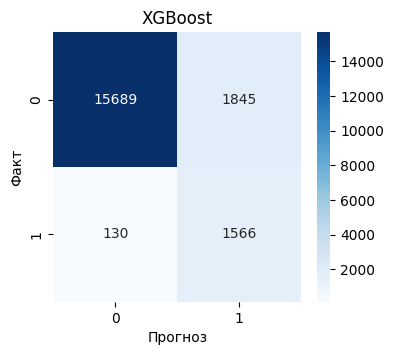

 LightGBM
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.46      0.92      0.61      1696

    accuracy                           0.90     19230
   macro avg       0.73      0.91      0.78     19230
weighted avg       0.94      0.90      0.91     19230



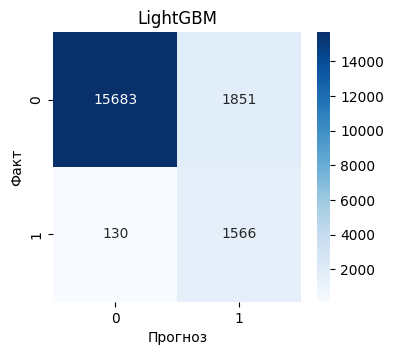

 CatBoost
              precision    recall  f1-score   support

           0       0.99      0.90      0.94     17534
           1       0.46      0.92      0.61      1696

    accuracy                           0.90     19230
   macro avg       0.73      0.91      0.78     19230
weighted avg       0.94      0.90      0.91     19230



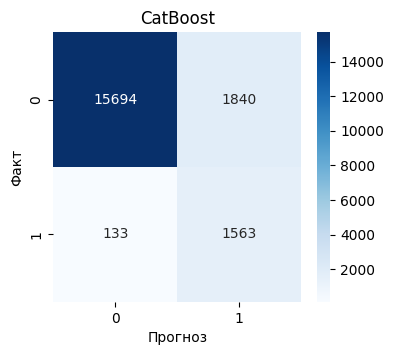

,precision (1),recall (1),F1 (1),accuracy
XGBoost,0.4591,0.9233,0.6133,0.8973
LightGBM,0.4583,0.9233,0.6126,0.8970
CatBoost,0.4593,0.9216,0.6131,0.8974


In [ ]:
!pip install catboost -q
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

neg, pos_n = (y_train == 0).sum(), (y_train == 1).sum()
boost_models = {
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             scale_pos_weight=neg / pos_n, eval_metric="logloss", random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                               scale_pos_weight=neg / pos_n, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=300, learning_rate=0.05, depth=4,
                                   auto_class_weights="Balanced", random_seed=42, verbose=0),
}
boost_results = {}
for name, model in boost_models.items():
    model.fit(X_train_enc, y_train)
    y_pred = model.predict(X_test_enc)
    print("=" * 60, "\n", name)
    print(classification_report(y_test, y_pred))
    plot_cm(y_test, y_pred, name)
    rep = classification_report(y_test, y_pred, output_dict=True)
    boost_results[name] = {"precision (1)": rep["1"]["precision"], "recall (1)": rep["1"]["recall"],
                           "F1 (1)": rep["1"]["f1-score"], "accuracy": rep["accuracy"]}
pd.DataFrame(boost_results).T.round(4)